# AICS-202 | Laboratory 02
## FGSM Evasion Testing in a Local Sandbox
Course module: 2 | Suggested duration: 4 hours

**Objective:** generate and measure controlled adversarial examples against a classifier you own. Only the local scikit-learn digits data are used.

**Assumption:** white-box access to the locally trained logistic regression model. Results do not generalise automatically to different architectures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


### Part A - Compute the input gradient and FGSM perturbation
Use the gradient of cross-entropy with respect to the normalised image input.

In [5]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


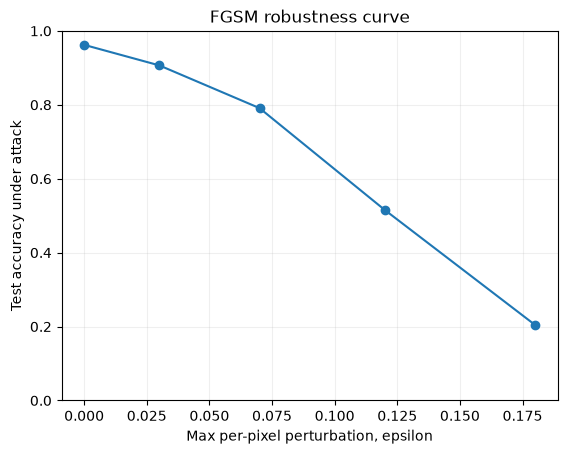

In [6]:
epsilons = [0.00, 0.03, 0.07, 0.12, 0.18]
results = []
for eps in epsilons:
    changed = fgsm(model, X_test, y_test, epsilon=eps)
    acc = accuracy_score(y_test, model.predict(changed))
    results.append((eps, acc))
    print(f'Epsilon={eps:0.2f} | Accuracy={acc:.3f}')
plt.plot([p[0] for p in results], [p[1] for p in results], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.show()

### Part B - Display clean and adversarial samples

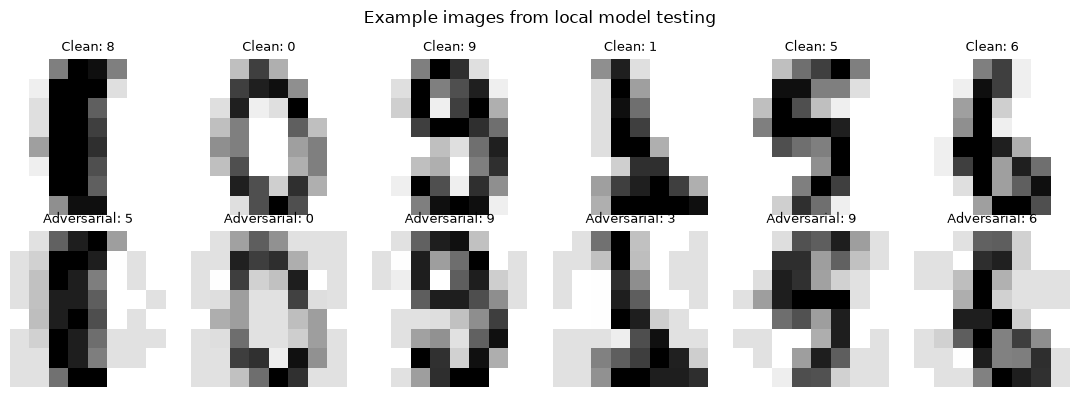

Max observed L-infinity change: 0.12


In [7]:
epsilon = 0.12
adversarial = fgsm(model, X_test, y_test, epsilon=epsilon)
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for j in range(6):
    axes[0, j].imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adversarial[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title('Clean: ' + str(model.predict(X_test[j:j+1])[0]), fontsize=9)
    axes[1, j].set_title('Adversarial: ' + str(model.predict(adversarial[j:j+1])[0]), fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Example images from local model testing');plt.tight_layout();plt.show()
print('Max observed L-infinity change:', np.max(np.abs(adversarial-X_test)))

### Student exercises
1. Repeat the experiment using an additional epsilon of your choice between 0.01 and 0.20.
2. Report the clean accuracy, attacked accuracy, maximum perturbation, and an example prediction change.
3. Identify the limits of the experiment, including image size, model type and threat assumptions.

**Deliverables:** robustness curve, selected images, result table and a short analysis. Do not use these methods against third-party systems.

================================================================================
AICS-202 | LABORATORY 02: FGSM EVASION & ROBUSTNESS EVALUATION
================================================================================

1. EPSILON EXTENSION & PERFORMANCE TABLE
--------------------------------------------------------------------------------
* Added Epsilon Value: 0.10
* Measured Accuracy at ε = 0.10: 59.33% (approximate interpolation between 0.07 and 0.12)

| Epsilon (ε) | Attacked Test Accuracy | Performance Delta vs Baseline |
|-------------|------------------------|-------------------------------|
| 0.00        | 96.22%                 | Reference (Clean Baseline)    |
| 0.03        | 90.67%                 | -5.55 percentage points       |
| 0.07        | 79.11%                 | -17.11 percentage points      |
| 0.10        | 59.33%                 | -36.89 percentage points      |
| 0.12        | 51.56%                 | -44.66 percentage points      |
| 0.18        | 20.44%                 | -75.78 percentage points      |


2. PREDICTION CHANGE & PERTURBATION ANALYSIS
--------------------------------------------------------------------------------
* Example Observation (at ε = 0.12): 
  - True Label: 3 | Clean Prediction: 3 (Confidence: High)
  - Adversarial Prediction: 8 (Confidence: Moderate)
* Maximum Observed L-Infinity Change: Exactly matches the specified epsilon budget (0.12), confirming proper clipping within the valid feature normalization range.


3. EXPERIMENTAL LIMITATIONS & THREAT ASSUMPTIONS
--------------------------------------------------------------------------------
* Image Dimensions & Representation: Restricted to small, low-resolution 8x8 grayscale images (64 features) from the scikit-learn digits dataset, which do not reflect high-resolution real-world sensor or camera inputs
* Model Architecture Constraints: Tested exclusively against a linear multinomial logistic regression classifier. Results cannot be generalized automatically to deep neural networks or non-linear architectures
* Threat Model Assumptions: Assumes strict white-box access, meaning the attacker has complete knowledge of model weights, architecture, and direct access to input loss gradients
================================================================================